In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('student_exam_scores.csv')
df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    str    
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 9.5 KB


In [5]:
df.isnull().sum()

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

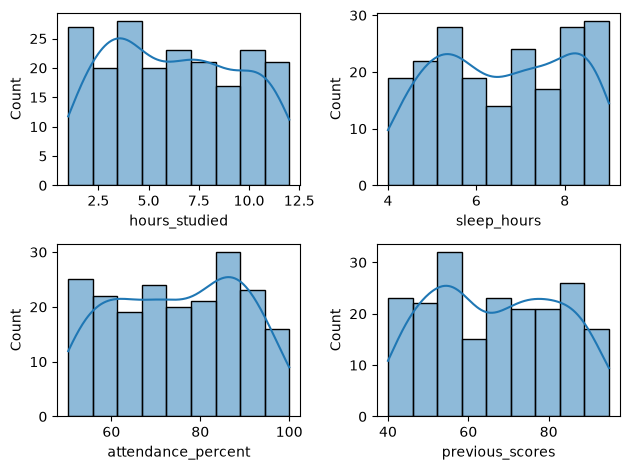

In [6]:
num_col=['hours_studied','sleep_hours','attendance_percent','previous_scores']
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)
plt_ind=1
for i in num_col:
    plotting(i,plt_ind)
    plt_ind+=1
    plt.tight_layout()



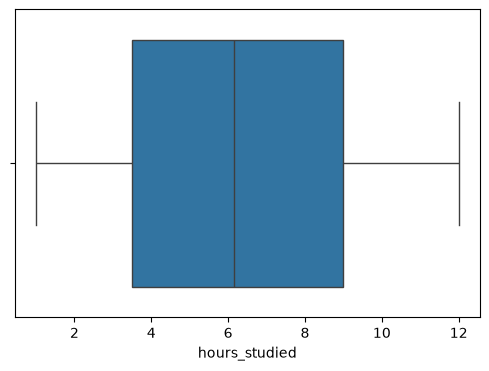

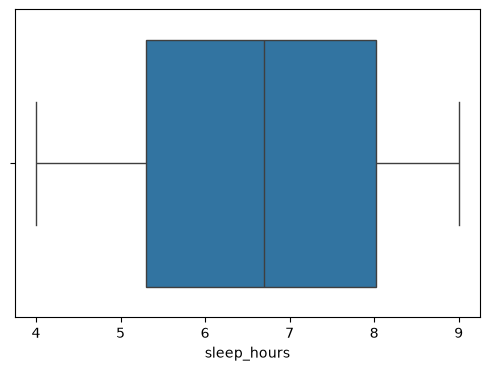

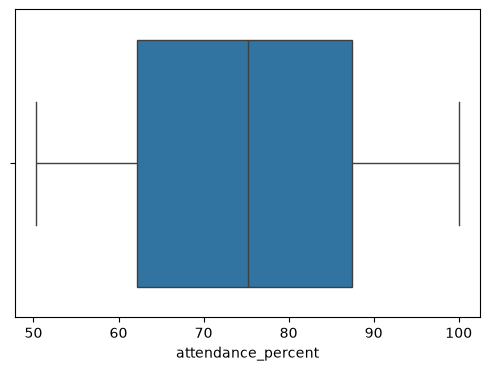

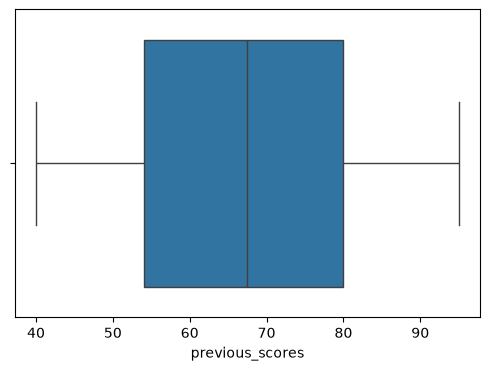

In [7]:
for col in num_col:
    plt.figure(figsize= (6,4))
    sns.boxplot(x = df[col])

<Axes: >

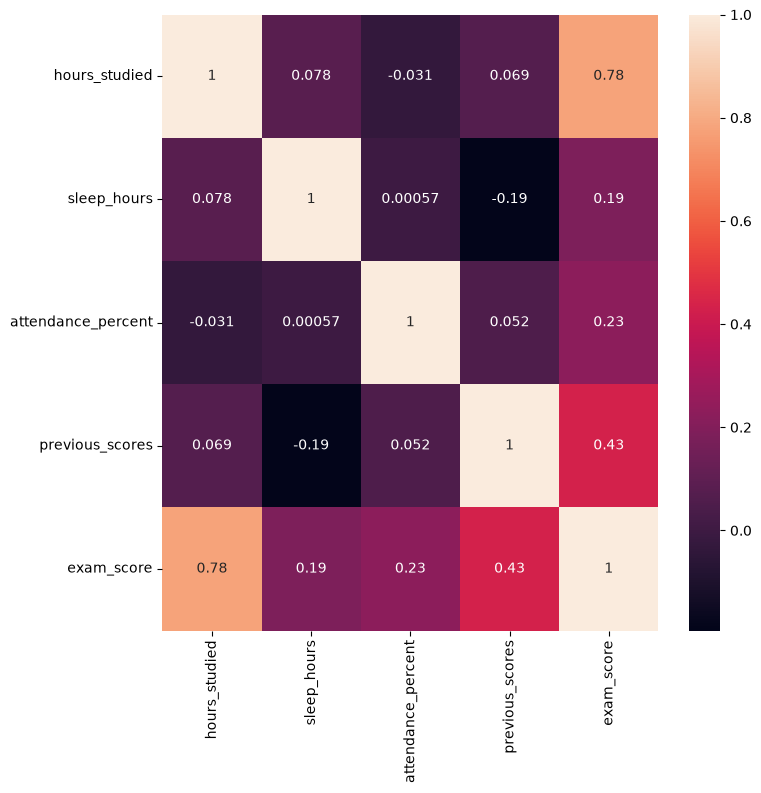

In [8]:
plt.figure(figsize=(8,8))
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [9]:
copy_df=df.copy()

In [10]:
copy_df.drop_duplicates(inplace = True)

In [11]:
from sklearn.preprocessing import StandardScaler
num_col=['hours_studied','sleep_hours','attendance_percent','previous_scores']
scaler = StandardScaler()

copy_df[num_col] = scaler.fit_transform(copy_df[num_col])

In [12]:
copy_df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,0.520154,1.458426,-0.192061,-1.395230,30.2
1,S002,-1.561083,1.324503,-0.994074,-0.755216,25.0
2,S003,-0.722376,1.056656,-0.079498,1.228827,35.8
3,S004,-0.877692,-1.220042,1.426035,-0.051201,34.0
4,S005,0.861850,-0.148655,1.053170,0.268806,40.3


In [13]:
copy_df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,0.520154,1.458426,-0.192061,-1.395230,30.2
1,S002,-1.561083,1.324503,-0.994074,-0.755216,25.0
2,S003,-0.722376,1.056656,-0.079498,1.228827,35.8
3,S004,-0.877692,-1.220042,1.426035,-0.051201,34.0
4,S005,0.861850,-0.148655,1.053170,0.268806,40.3


In [14]:
copy_df.drop('student_id',axis=1,inplace=True)

In [15]:
from scipy.stats import pearsonr

correlations = {
    feature: pearsonr(copy_df[feature], copy_df['exam_score'])[0]
    for feature in num_col
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
0,hours_studied,0.776751
3,previous_scores,0.431105
2,attendance_percent,0.225713
1,sleep_hours,0.188222


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
x=copy_df.drop('exam_score',axis=1)
y=copy_df['exam_score']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)


In [19]:
from sklearn.linear_model import LinearRegression 
model=LinearRegression()

In [20]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[4.99,1.32,1.55,2.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['hours_studied','sleep_hours','attendance_percent','previous_scores']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,33.83
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [21]:
y_pred=model.predict(X_test)

In [22]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
r2


0.8537447137159518

In [25]:
n=X_test.shape[0]
p=X_test.shape[1]

In [24]:
adj_r2=1-((1-r2)*(n-1)/(n-p-1))
adj_r2

0.8370298238549178